# Notebook 8 – Distribution Analysis

# Question 1 — What is a Distribution?

### What is a Distribution, and what does it tell us about numerical data?

## Step 1: Understand the concept

A distribution shows how the values of a numerical variable are spread across different ranges.

A distribution helps us understand:

- Shape of the data
- Center of the data
- Spread of the data
- Skewness
- Presence of unusual values or outliers

For example, we can study how customer Tenure, MonthlyCharges, and TotalCharges are distributed.

## Step 2: Demonstrate the concept

In the Telco Customer Churn dataset, we will analyze:

- Tenure
- MonthlyCharges
- TotalCharges

We can use histograms and density plots to understand the distribution of these features.

### AI/ML Use

Understanding feature distributions helps us choose suitable preprocessing and machine learning techniques.


## Step 3: Implementation the concept

In [1]:


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

numerical_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

print("Dataset Loaded Successfully!")
print("Dataset Shape:", df.shape)

Dataset Loaded Successfully!
Dataset Shape: (7043, 21)


## Code Explanation

- The dataset is loaded using Pandas.
- `TotalCharges` is converted into numeric format.
- Three important numerical features are selected for distribution analysis.

These features will be used throughout this notebook.

# Question 2 — Analyze the Shape of Numerical Distributions

### What is the shape of the distributions of the important numerical features?

## Step 1: Understand the concept

The shape of a distribution describes how the data values are arranged.

Common shapes include:

- Normal distribution
- Uniform distribution
- Symmetric distribution
- Left-skewed distribution
- Right-skewed distribution

A histogram or density plot can help us identify the shape visually.

## Step 2: Demonstrate the concept

We will create histograms with density curves for:

- Tenure
- MonthlyCharges
- TotalCharges

The shape of each distribution can then be compared.


## Step 3: Implementation the concept

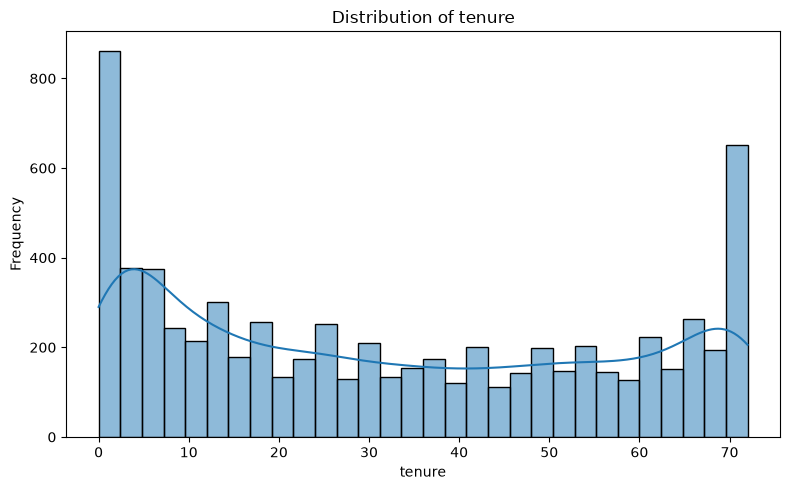

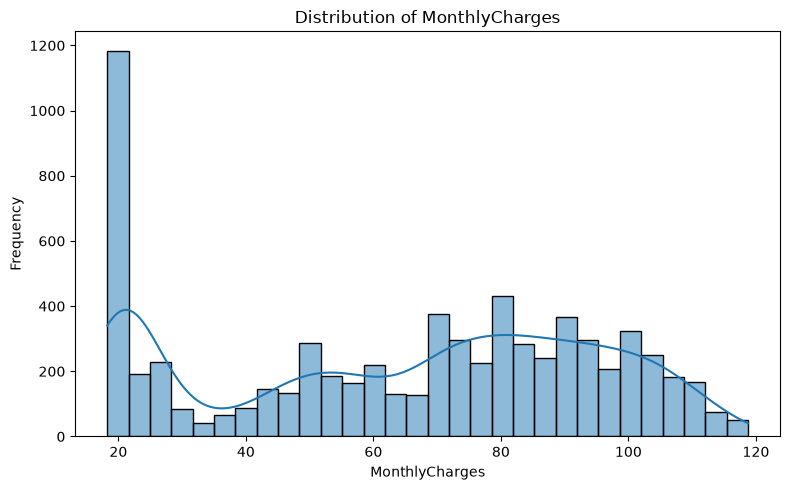

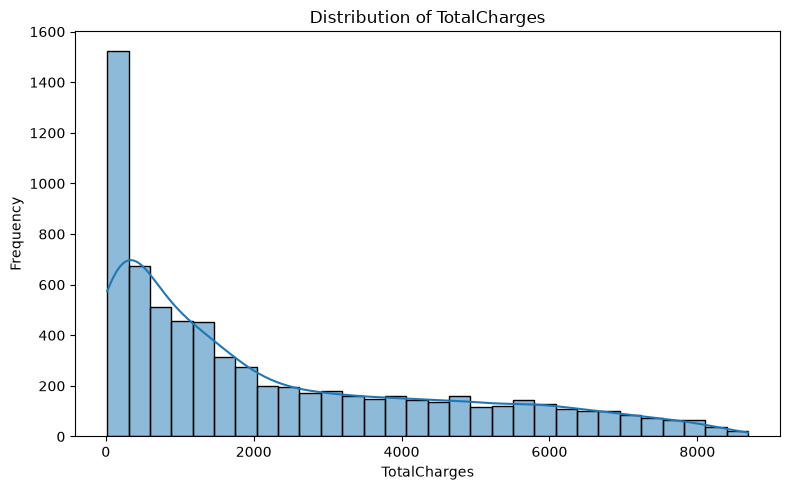

In [2]:


for column in numerical_features:

    data = df[column].dropna()

    plt.figure(figsize=(8, 5))

    sns.histplot(
        data,
        bins=30,
        kde=True
    )

    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Frequency")

    plt.tight_layout()
    plt.show()

## Code Explanation

- `sns.histplot()` creates the histogram.
- `bins=30` divides the values into 30 intervals.
- `kde=True` adds a smooth density curve.

### Expected Insight

The histogram and density curve help identify whether the distribution is:

- Symmetric
- Left-skewed
- Right-skewed
- Approximately normal
- Irregular

# Question 3 — Normal Distribution

### What is a Normal Distribution, and do the numerical features follow a normal distribution?

## Step 1: Understand the concept

A Normal Distribution is a symmetric, bell-shaped distribution.

In a perfectly normal distribution:

- Mean ≈ Median ≈ Mode
- Most values are near the center
- Fewer values occur toward the ends
- The distribution is approximately symmetric

A normal distribution has low skewness and follows a bell-shaped pattern.

## Step 2: Demonstrate the concept

We can compare the Mean and Median of each numerical feature.

If the mean and median are close and the histogram looks approximately bell-shaped, the feature may be approximately normally distributed.

However, visual inspection and skewness should be considered together.


## Step 3: Implementation the concept

In [3]:


for column in numerical_features:

    data = df[column].dropna()

    mean_value = data.mean()
    median_value = data.median()

    print(f"\n{column}")
    print("Mean:", round(mean_value, 2))
    print("Median:", round(median_value, 2))


tenure
Mean: 32.37
Median: 29.0

MonthlyCharges
Mean: 64.76
Median: 70.35

TotalCharges
Mean: 2283.3
Median: 1397.48


## Code Explanation

- `mean()` calculates the average.
- `median()` finds the middle value.

If Mean and Median are close, the distribution may be relatively symmetric.

However, this alone does not prove that the data is normally distributed.

# Question 4 — Uniform Distribution


### What is a Uniform Distribution, and do the important numerical features show a uniform pattern?

## Step 1: Understand the concept

A Uniform Distribution occurs when values are approximately equally likely across a given range.

Its histogram generally looks relatively flat.

For example, if values between 1 and 10 occur with approximately equal frequency, the distribution is close to uniform.

Real-world customer data does not necessarily follow a uniform distribution.

## Step 2: Demonstrate the concept

We can inspect the histograms of:

- Tenure
- MonthlyCharges
- TotalCharges

A relatively flat histogram may indicate a more uniform-like distribution.

A strong peak or long tail indicates that the distribution is not uniform.


## Step 3: Implementation the concept

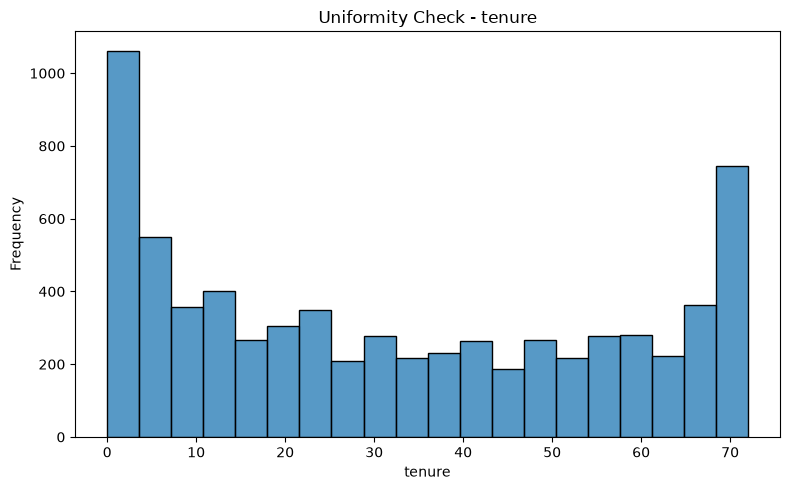

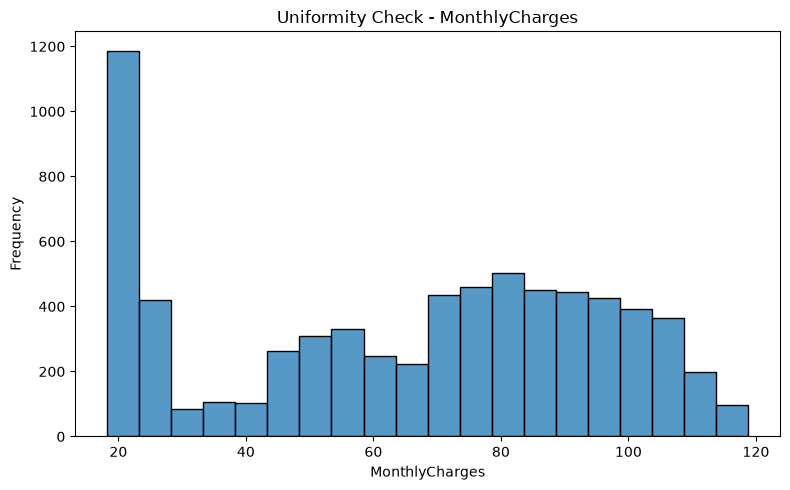

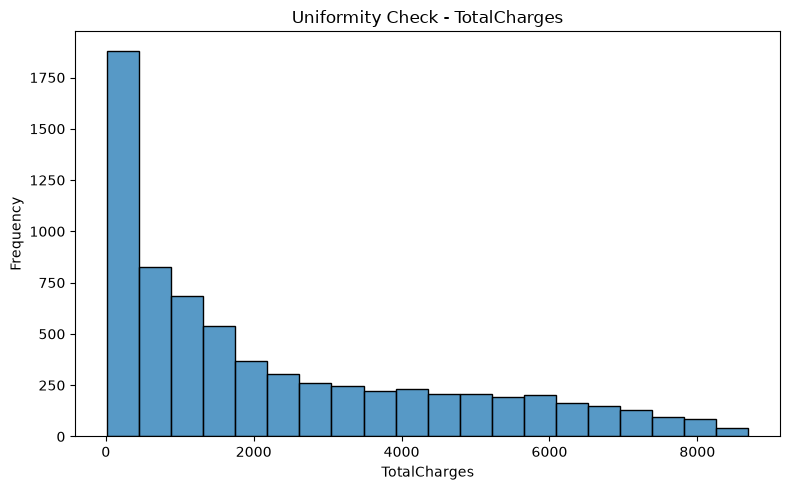

In [4]:


for column in numerical_features:

    data = df[column].dropna()

    plt.figure(figsize=(8, 5))

    sns.histplot(
        data,
        bins=20
    )

    plt.title(f"Uniformity Check - {column}")
    plt.xlabel(column)
    plt.ylabel("Frequency")

    plt.tight_layout()
    plt.show()

## Code Explanation

The histogram shows how frequently values occur across the feature range.

### Expected Insight

If the bars are approximately equal in height, the distribution may look uniform.

If some ranges have much higher frequencies than others, the feature is not uniformly distributed.

# Question 5 — Analyze Skewness

### What is Skewness, and what type of skewness exists in the numerical features?


## Step 1: Understand the concept

Skewness measures the asymmetry of a distribution.

General interpretation:

- Skewness ≈ 0 → Approximately symmetric
- Positive skewness → Right-skewed
- Negative skewness → Left-skewed

### Right-Skewed

The distribution has a longer tail toward higher values.

### Left-Skewed

The distribution has a longer tail toward lower values.

## Step 2: Demonstrate the concept

We will calculate the skewness of:

- Tenure
- MonthlyCharges
- TotalCharges

The skewness value will help us understand the direction of asymmetry.


## Step 3: Implementation the concept

In [5]:


for column in numerical_features:

    skewness = df[column].skew()

    print(
        f"{column}: Skewness = {skewness:.2f}"
    )

tenure: Skewness = 0.24
MonthlyCharges: Skewness = -0.22
TotalCharges: Skewness = 0.96


## Code Explanation

`.skew()` calculates the skewness of a numerical feature.

Interpretation:

- Value close to 0 → More symmetric
- Positive value → Right-skewed
- Negative value → Left-skewed

The larger the absolute value, the stronger the asymmetry.

# Question 6 — Analyze Kurtosis


### What is Kurtosis, and what does it tell us about the distribution?

## Step 1: Understand the concept

Kurtosis describes the shape of the distribution, especially the heaviness of its tails and the presence of extreme values.

In Pandas, `.kurt()` returns excess kurtosis.

General interpretation:

- Kurtosis ≈ 0 → Similar tail behavior to a normal distribution
- Positive kurtosis → Heavier tails and more extreme values
- Negative kurtosis → Lighter tails and fewer extreme values

## Step 2: Demonstrate the concept

We will calculate kurtosis for:

- Tenure
- MonthlyCharges
- TotalCharges

Higher positive kurtosis can indicate that extreme observations may be more common.


## Step 3: Implementation the concept

In [6]:


for column in numerical_features:

    kurtosis = df[column].kurt()

    print(
        f"{column}: Kurtosis = {kurtosis:.2f}"
    )

tenure: Kurtosis = -1.39
MonthlyCharges: Kurtosis = -1.26
TotalCharges: Kurtosis = -0.23


## Code Explanation

`.kurt()` calculates excess kurtosis.

The value helps us understand the tail behavior of the distribution.

### Expected Insight

A high positive value may indicate heavier tails and possible extreme observations.

# Question 7 — Identify Symmetric, Left-Skewed and Right-Skewed Distributions


### How can we identify Symmetric, Left-Skewed, and Right-Skewed distributions?

## Step 1: Understand the concept

### Symmetric Distribution

Both sides of the distribution are approximately balanced.

Skewness is close to 0.

### Right-Skewed Distribution

The right side has a longer tail.

Skewness is positive.

### Left-Skewed Distribution

The left side has a longer tail.

Skewness is negative.

## Step 2: Demonstrate the concept

We will use the skewness value to classify each numerical feature.

Classification:

- -0.5 to +0.5 → Approximately Symmetric
- Greater than +0.5 → Right-Skewed
- Less than -0.5 → Left-Skewed

These are practical guidelines rather than strict rules.


## Step 3: Implementation the concept

In [7]:


for column in numerical_features:

    skewness = df[column].skew()

    if skewness > 0.5:
        distribution_type = "Right-Skewed"

    elif skewness < -0.5:
        distribution_type = "Left-Skewed"

    else:
        distribution_type = "Approximately Symmetric"

    print(
        f"{column}: "
        f"{skewness:.2f} → {distribution_type}"
    )

tenure: 0.24 → Approximately Symmetric
MonthlyCharges: -0.22 → Approximately Symmetric
TotalCharges: 0.96 → Right-Skewed


## Code Explanation

The code uses the skewness value to classify the distribution.

### Expected Insight

Each numerical feature will be classified as:

- Approximately Symmetric
- Right-Skewed
- Left-Skewed

The classification should also be compared with the histogram.

# Question 8 — Analyze Center of the Distribution


### How can we identify the center of each numerical distribution?

## Step 1: Understand the concept

The center represents the typical or central value of the data.

Common measures are:

- Mean
- Median
- Mode

For numerical distribution analysis, Mean and Median are especially useful.

In a symmetric distribution, Mean and Median are usually close.

In a skewed distribution, Mean and Median can differ.

## Step 2: Demonstrate the concept

We will compare the Mean and Median for:

- Tenure
- MonthlyCharges
- TotalCharges

This helps us understand the center of each distribution.


## Step 3: Implementation the concept


In [8]:


for column in numerical_features:

    data = df[column].dropna()

    print(f"\n--- {column} ---")
    print("Mean:", round(data.mean(), 2))
    print("Median:", round(data.median(), 2))


--- tenure ---
Mean: 32.37
Median: 29.0

--- MonthlyCharges ---
Mean: 64.76
Median: 70.35

--- TotalCharges ---
Mean: 2283.3
Median: 1397.48


## Code Explanation

Mean and Median are calculated for each numerical feature.

### Expected Insight

If Mean and Median are very different, the distribution may be affected by skewness or extreme values.

# Question 9 — Analyze Spread of the Distribution


### How can we measure the spread of each numerical distribution?

## Step 1: Understand the concept

Spread tells us how widely the data values are distributed.

Common measures include:

- Range
- Variance
- Standard Deviation
- Interquartile Range (IQR)

A larger spread means the values are more widely distributed.

## Step 2: Demonstrate the concept

We will calculate:

- Minimum
- Maximum
- Range
- Standard Deviation
- IQR

for each numerical feature.


## Step 3: Implementation the concept

In [9]:


for column in numerical_features:

    data = df[column].dropna()

    minimum = data.min()
    maximum = data.max()
    data_range = maximum - minimum
    std = data.std()

    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1

    print(f"\n--- {column} ---")
    print("Minimum:", round(minimum, 2))
    print("Maximum:", round(maximum, 2))
    print("Range:", round(data_range, 2))
    print("Standard Deviation:", round(std, 2))
    print("IQR:", round(IQR, 2))


--- tenure ---
Minimum: 0
Maximum: 72
Range: 72
Standard Deviation: 24.56
IQR: 46.0

--- MonthlyCharges ---
Minimum: 18.25
Maximum: 118.75
Range: 100.5
Standard Deviation: 30.09
IQR: 54.35

--- TotalCharges ---
Minimum: 18.8
Maximum: 8684.8
Range: 8666.0
Standard Deviation: 2266.77
IQR: 3393.29


## Code Explanation

- Range = Maximum - Minimum
- Standard Deviation measures average spread around the mean.
- IQR measures the spread of the middle 50% of the data.

### Expected Insight

These measures help us understand how widely the values are distributed.

# Question 10 — Analyze Presence of Outliers

### How can we identify the presence of Outliers in numerical distributions?


## Step 1: Understand the concept

Outliers are observations that are unusually far from the majority of the data.

A Box Plot can visually show potential outliers.

The IQR method can also identify them mathematically.

Upper Bound = Q3 + 1.5 × IQR

Lower Bound = Q1 - 1.5 × IQR

## Step 2: Demonstrate the concept

We will use the IQR method to count potential outliers in:

- Tenure
- MonthlyCharges
- TotalCharges

We will also visualize them using Box Plots.


## Step 3: Implementation the concept

In [10]:


for column in numerical_features:

    data = df[column].dropna()

    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = data[
        (data < lower_bound) |
        (data > upper_bound)
    ]

    print(f"\n--- {column} ---")
    print("Potential Outliers:", len(outliers))
    print("Lower Bound:", round(lower_bound, 2))
    print("Upper Bound:", round(upper_bound, 2))


--- tenure ---
Potential Outliers: 0
Lower Bound: -60.0
Upper Bound: 124.0

--- MonthlyCharges ---
Potential Outliers: 0
Lower Bound: -46.02
Upper Bound: 171.38

--- TotalCharges ---
Potential Outliers: 0
Lower Bound: -4688.48
Upper Bound: 8884.67


## Code Explanation

The IQR method identifies values outside the lower and upper boundaries.

These values are considered potential outliers.

### Important

Potential outliers should be investigated before deciding whether to remove, transform, or retain them.

# Question 11 — Complete Distribution Analysis


### How can we summarize the Shape, Center, Spread, Skewness, and Outliers of important numerical features?

## Step 1: Understand the concept

A complete distribution analysis should examine:

### Shape
How the values are arranged.

### Center
The typical value represented by Mean and Median.

### Spread
How widely the values are distributed.

### Skewness
Whether the distribution is symmetric or skewed.

### Outliers
Whether unusual observations are present.

## Step 2: Demonstrate the concept

For each numerical feature, we will combine:

- Mean
- Median
- Standard Deviation
- Skewness
- Kurtosis
- IQR
- Number of potential outliers

This gives us a complete summary of the distribution.


## Step 3: Implementation the concept

In [11]:


distribution_summary = []

for column in numerical_features:

    data = df[column].dropna()

    mean_value = data.mean()
    median_value = data.median()
    std_value = data.std()
    skewness = data.skew()
    kurtosis = data.kurt()

    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = data[
        (data < lower_bound) |
        (data > upper_bound)
    ]

    distribution_summary.append({
        "Feature": column,
        "Mean": round(mean_value, 2),
        "Median": round(median_value, 2),
        "Std": round(std_value, 2),
        "Skewness": round(skewness, 2),
        "Kurtosis": round(kurtosis, 2),
        "IQR": round(IQR, 2),
        "Potential_Outliers": len(outliers)
    })

summary_df = pd.DataFrame(distribution_summary)

print(summary_df)

          Feature     Mean   Median      Std  Skewness  Kurtosis      IQR  \
0          tenure    32.37    29.00    24.56      0.24     -1.39    46.00   
1  MonthlyCharges    64.76    70.35    30.09     -0.22     -1.26    54.35   
2    TotalCharges  2283.30  1397.48  2266.77      0.96     -0.23  3393.29   

   Potential_Outliers  
0                   0  
1                   0  
2                   0  


## Code Explanation

This code combines the important distribution measures into one summary table.

For every numerical feature, we can compare:

- Center → Mean and Median
- Spread → Standard Deviation and IQR
- Shape → Skewness and Kurtosis
- Outliers → Number of potential outliers

This table provides a quick overview of the numerical distributions.

# Notebook 8 – Distribution Analysis Summary

The important numerical features analyzed were:

- Tenure
- MonthlyCharges
- TotalCharges

### Shape of Distribution

Histograms and density curves were used to understand whether the distributions are symmetric, normal-like, skewed, or irregular.

### Center

Mean and Median were used to identify the central values of the distributions.

### Spread

Range, Standard Deviation, and IQR were used to understand how widely the values are distributed.

### Skewness

Skewness was used to identify:

- Approximately symmetric distributions
- Right-skewed distributions
- Left-skewed distributions

### Kurtosis

Kurtosis was used to understand tail behavior and the presence of extreme values.

### Outliers

The IQR method and Box Plots were used to identify potential outliers.

### Important Conclusion

An outlier should not automatically be removed.

The distribution should be understood first, and the outlier should be investigated before deciding whether to:

- Retain it
- Remove it
- Transform it

### Overall Conclusion

Distribution Analysis helps us understand the behavior, shape, center, spread, skewness, and unusual observations in numerical features before applying machine learning models.